
# Statistical Analysis of Seasonal and Spatial Variations in River Water Quality

### An Empirical Investigation of Nitrate Concentration and Dissolved Oxygen Across River Sections and Seasons

**Author:** Tanay Sanjay Shinde

**Programme:** M.Sc. Data Science

**Intended Intake:** Summer Semester 2027

---

## 1. Research Overview

Water quality is an important indicator of aquatic environmental conditions. 
Its characteristics can vary across geographical locations and seasonal periods 
due to differences in environmental and hydrological conditions.

This project investigates the seasonal and spatial variations in river water 
quality using statistical analysis and data visualisation.

The investigation focuses on two water-quality indicators:

- **Nitrate concentration (mg/L):** Represents the concentration of nitrate 
  measured in the water.
- **Dissolved oxygen concentration (mg/L):** Represents the amount of oxygen 
  dissolved in the water.

Measurements are analysed across five river sections and four seasonal periods.

The study applies exploratory and inferential statistical methods to identify 
patterns, evaluate differences and examine potential relationships between 
seasonal and geographical factors.



## 1.2 Research Questions

The analysis is guided by the following research questions:

**RQ1:** Does nitrate concentration vary significantly across seasons?

**RQ2:** Does dissolved oxygen concentration vary significantly across seasons?

**RQ3:** Are there significant differences in nitrate and dissolved oxygen 
concentrations across the five river sections?

**RQ4:** Is there an interaction between season and river section that 
influences the observed water-quality measurements?



# 2. Dataset Description and Understanding

## 2.1 Dataset Overview

The dataset used in this investigation contains observations 
of water-quality measurements collected across different 
river sections and seasonal periods.

The dataset consists of categorical variables describing 
the sampling location and season, along with numerical 
measurements representing water-quality indicators.

The analysis focuses on two response variables:

- Nitrate concentration, measured in mg/L.
- Dissolved oxygen concentration, measured in mg/L.

The categorical variables are used to investigate spatial 
and seasonal differences in the measured water-quality indicators.

Before conducting statistical analysis, the dataset will be 
examined to understand its structure, variable types, 
observation counts and overall characteristics.


In [2]:

# Data manipulation and numerical computation
import pandas as pd
import numpy as np

# Statistical analysis
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")


In [ ]:

# Load the dataset
df = pd.read_csv("waterquality.csv", sep=";")

df.head()


,ID,river_section,saison,nitrate_mgL,oxygen_mgL
0,1,A1_headwaters,spring,5.540,10.711
1,2,A1_headwaters,spring,3.328,9.937
2,3,A1_headwaters,spring,5.742,10.499
3,4,A1_headwaters,spring,7.822,10.405
4,5,A1_headwaters,spring,8.843,10.245


In [4]:

# Dataset dimensions
print("Dataset shape:", df.shape)

# Column names
print("\nColumn names:")
print(df.columns.tolist())

# Data types and non-null observations
print("\nDataset information:")
df.info()

# First five observations
print("\nFirst five observations:")
display(df.head())


Dataset shape: (900, 5)

Column names:
['ID', 'river_section', 'saison', 'nitrate_mgL', 'oxygen_mgL']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ID             900 non-null    int64  
 1   river_section  900 non-null    object 
 2   saison         900 non-null    object 
 3   nitrate_mgL    900 non-null    float64
 4   oxygen_mgL     900 non-null    float64
dtypes: float64(2), int64(1), object(2)
memory usage: 35.3+ KB

First five observations:


,ID,river_section,saison,nitrate_mgL,oxygen_mgL
0,1,A1_headwaters,spring,5.540,10.711
1,2,A1_headwaters,spring,3.328,9.937
2,3,A1_headwaters,spring,5.742,10.499
3,4,A1_headwaters,spring,7.822,10.405
4,5,A1_headwaters,spring,8.843,10.245



## 2.4 Data Quality Assessment

Before conducting statistical analysis, it is necessary to 
evaluate the completeness and consistency of the dataset.

The following checks will be performed:

- Identification of missing values.
- Detection of duplicate observations and identifiers.
- Examination of unique categorical values.
- Verification of observation frequencies across river 
  sections and seasons.

These checks help determine whether the dataset is suitable 
for subsequent exploratory and inferential statistical analysis.


In [6]:
# Count missing values in each column
missing_values = df.isnull().sum()

# Calculate missing-value percentages
missing_percentage = (df.isnull().mean() * 100).round(2)

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage (%)": missing_percentage
})

display(missing_summary)

,Missing Values,Missing Percentage (%)
ID,0,0.0
river_section,0,0.0
saison,0,0.0
nitrate_mgL,0,0.0
oxygen_mgL,0,0.0


In [7]:
# Check duplicate rows
duplicate_rows = df.duplicated().sum()

# Check duplicate IDs
duplicate_ids = df["ID"].duplicated().sum()

print("Number of duplicate rows:", duplicate_rows)
print("Number of duplicate IDs:", duplicate_ids)

Number of duplicate rows: 0
Number of duplicate IDs: 0


In [8]:
# Unique river sections
print("River sections:")
print(df["river_section"].unique())

print("\nNumber of river sections:")
print(df["river_section"].nunique())

# Unique seasons
print("\nSeasons:")
print(df["saison"].unique())

print("\nNumber of seasons:")
print(df["saison"].nunique())

River sections:
['A1_headwaters' 'A2_upper_course' 'A3_middle_course' 'A4_lower_course'
 'A5_mouth']

Number of river sections:
5

Seasons:
['spring' 'summer' 'autumn' 'winter']

Number of seasons:
4


In [9]:
# Observations per river section
print("Observations per river section:")
display(df["river_section"].value_counts().sort_index())

# Observations per season
print("\nObservations per season:")
display(df["saison"].value_counts().sort_index())

# Cross-tabulation of river section and season
print("\nObservations per river section and season:")

observation_table = pd.crosstab(
    df["river_section"],
    df["saison"]
)

display(observation_table)

Observations per river section:


river_section
A1_headwaters       180
A2_upper_course     180
A3_middle_course    180
A4_lower_course     180
A5_mouth            180
Name: count, dtype: int64


Observations per season:


saison
autumn    225
spring    225
summer    225
winter    225
Name: count, dtype: int64


Observations per river section and season:


saison,autumn,spring,summer,winter
river_section,,,,
A1_headwaters,45,45,45,45
A2_upper_course,45,45,45,45
A3_middle_course,45,45,45,45
A4_lower_course,45,45,45,45
A5_mouth,45,45,45,45



## 2.5 Data Quality Assessment — Findings

The initial data-quality assessment produced the following findings:

- No missing values were identified across the five variables.
- No duplicate rows were detected.
- No duplicate observation identifiers were found.
- All five river sections are represented in the dataset.
- All four seasonal categories are represented in the dataset.

### Observation Distribution

Each river section contains 180 observations, distributed equally
across the four seasons.

Each season contains 225 observations across the five river sections.

Every river-section and season combination contains exactly
45 observations.

Consequently, the dataset follows a balanced factorial structure.

The total number of observations can be expressed as:

\[
N = a * b * n
\]

where:

- \(a = 5\): number of river sections
- \(b = 4\): number of seasons
- \(n = 45\): observations per combination

Therefore:

\[
N = 5 * 4 * 45 = 900
\]

This balanced structure provides a suitable foundation for
investigating spatial and seasonal differences using factorial
statistical methods.

However, data completeness and balance alone do not establish
the independence of observations or verify the assumptions
required for inferential statistical tests.



# 3. Descriptive Statistical Analysis

Descriptive statistics provide a numerical summary of the
distribution and variability of the observed measurements.

In this section, the two response variables, nitrate concentration
and dissolved oxygen concentration, are examined using measures
of central tendency, dispersion and distribution.

The following statistical measures will be considered:

- Mean and median
- Standard deviation and variance
- Minimum and maximum values
- Range
- First and third quartiles
- Interquartile range

The analysis initially considers the complete dataset before
examining differences across seasons and river sections.


In [11]:
# Select numerical response variables
response_variables = ["nitrate_mgL", "oxygen_mgL"]

# Calculate descriptive statistics
descriptive_stats = df[response_variables].describe().T

# Add variance and range
descriptive_stats["variance"] = df[response_variables].var()
descriptive_stats["range"] = (
    df[response_variables].max() - df[response_variables].min()
)

# Display results
display(descriptive_stats.round(3))

,count,mean,std,min,25%,50%,75%,max,variance,range
nitrate_mgL,900.0,8.812,2.873,1.510,6.762,8.887,10.927,16.444,8.256,14.934
oxygen_mgL,900.0,8.971,1.425,4.608,8.058,9.264,9.979,12.167,2.031,7.559


### 3.1 Overall Descriptive Statistics

The descriptive statistical analysis was performed on 900 observations for each of the two water-quality indicators: nitrate concentration and dissolved oxygen concentration. Measures of central tendency and dispersion were calculated to summarise the overall characteristics of the observed measurements.

**Nitrate Concentration.** The mean nitrate concentration was 8.812 mg/L, with a median of 8.887 mg/L and a standard deviation of 2.873 mg/L. The observed concentrations ranged from 1.510 mg/L to 16.444 mg/L, yielding an overall range of 14.934 mg/L. The relatively small difference between the mean and median indicates that the two measures of central tendency are closely aligned, although the distribution requires further examination to establish its shape.

**Dissolved Oxygen Concentration.** The mean dissolved oxygen concentration was 8.971 mg/L, while the median was 9.264 mg/L. The corresponding standard deviation was 1.425 mg/L. Observed concentrations ranged from 4.608 mg/L to 12.167 mg/L, resulting in a range of 7.559 mg/L. The mean being lower than the median suggests that relatively low observations may influence the overall average.

**Comparative Interpretation.** The descriptive results indicate greater absolute dispersion in nitrate measurements than in dissolved oxygen measurements, as reflected by their respective standard deviations of 2.873 mg/L and 1.425 mg/L. However, these summary statistics alone are insufficient to establish the underlying distributional characteristics or explain the sources of variability. Therefore, graphical exploration and further statistical investigation are necessary to examine the distributions and identify potential seasonal and spatial patterns.

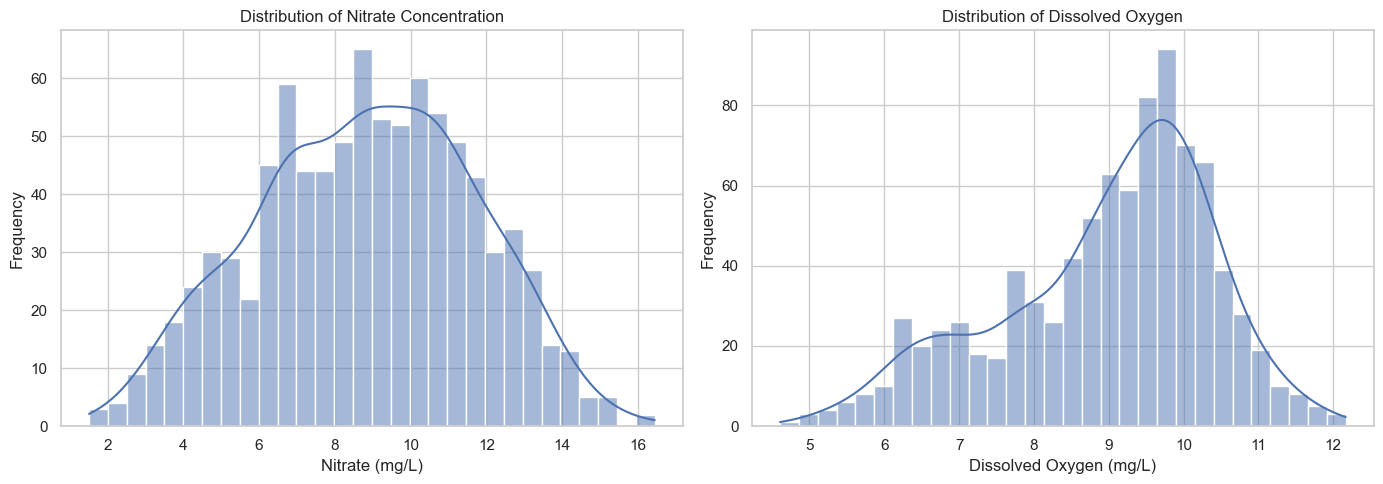

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df,
    x="nitrate_mgL",
    kde=True,
    bins=30,
    ax=axes[0]
)
axes[0].set_title("Distribution of Nitrate Concentration")
axes[0].set_xlabel("Nitrate (mg/L)")
axes[0].set_ylabel("Frequency")

sns.histplot(
    data=df,
    x="oxygen_mgL",
    kde=True,
    bins=30,
    ax=axes[1]
)
axes[1].set_title("Distribution of Dissolved Oxygen")
axes[1].set_xlabel("Dissolved Oxygen (mg/L)")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [13]:
distribution_stats = df[["nitrate_mgL", "oxygen_mgL"]].agg(
    ["mean", "median", "std", "skew"]
).T

distribution_stats["kurtosis"] = df[
    ["nitrate_mgL", "oxygen_mgL"]
].kurtosis()

display(distribution_stats.round(3))

,mean,median,std,skew,kurtosis
nitrate_mgL,8.812,8.887,2.873,-0.094,-0.593
oxygen_mgL,8.971,9.264,1.425,-0.616,-0.200


### 3.2 Distributional Analysis
The distributions of nitrate and dissolved oxygen concentrations were 
examined using histograms with kernel density estimates, together with numerical measures of skewness and excess kurtosis.

Nitrate concentration exhibited an approximately symmetric distribution, with a skewness coefficient of −0.094. The mean (8.812 mg/L) was close to the median (8.887 mg/L), supporting the visual observation of limited asymmetry. Its excess kurtosis of −0.593 suggests a comparatively flatter distribution with lighter tails than the normal distribution.

In contrast, dissolved oxygen concentration exhibited a more pronounced negative skew, with a skewness coefficient of −0.616. Its mean (8.971 mg/L) was lower than its median (9.264 mg/L), consistent with a distribution extending towards lower concentration values. The excess kurtosis of −0.200 indicates a distribution that is slightly flatter than the normal reference distribution.

Overall, nitrate concentrations displayed greater symmetry than dissolved oxygen concentrations. These findings provide an initial description of the response-variable distributions; however, they do not independently establish normality. The normality assumption relevant to the subsequent analysis of variance will therefore be evaluated using the fitted model residuals.

### 3.3 Identification of Potential Outliers

Boxplots were constructed to examine the spread of nitrate and
dissolved oxygen concentrations and identify potential extreme
observations. The interquartile range (IQR) was used as the basis
for identifying observations outside the conventional boxplot
whisker limits.

Observations identified as potential outliers will be retained
unless further investigation provides evidence of measurement
or data-recording errors.

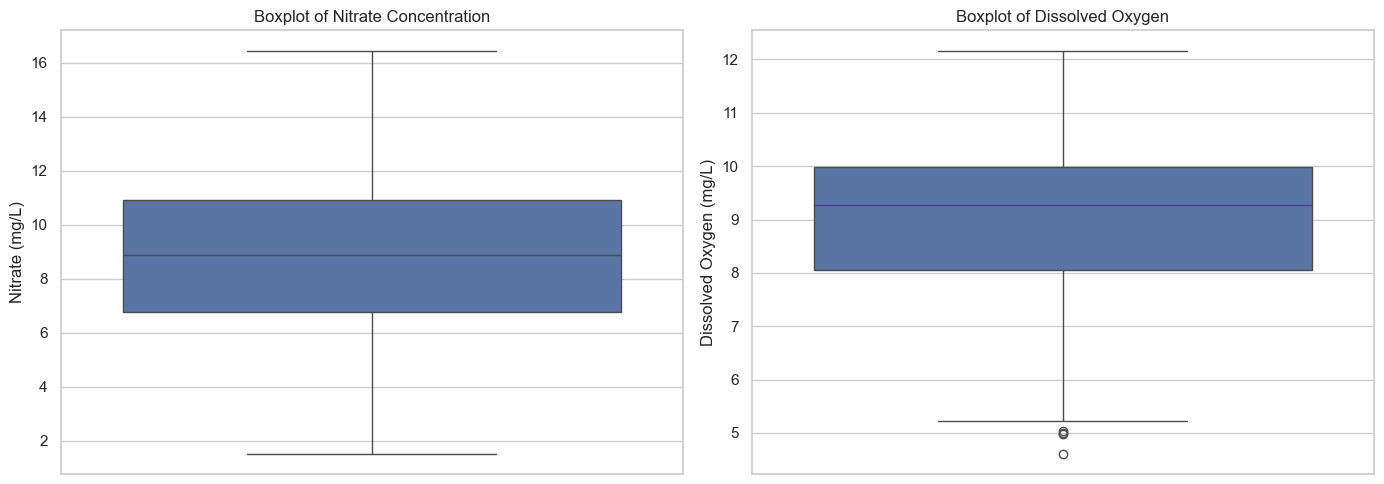

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(y=df["nitrate_mgL"], ax=axes[0])
axes[0].set_title("Boxplot of Nitrate Concentration")
axes[0].set_ylabel("Nitrate (mg/L)")

sns.boxplot(y=df["oxygen_mgL"], ax=axes[1])
axes[1].set_title("Boxplot of Dissolved Oxygen")
axes[1].set_ylabel("Dissolved Oxygen (mg/L)")

plt.tight_layout()
plt.show()

In [15]:
for column in ["nitrate_mgL", "oxygen_mgL"]:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(f"\nVariable: {column}")
    print(f"Q1: {Q1:.3f}")
    print(f"Q3: {Q3:.3f}")
    print(f"IQR: {IQR:.3f}")
    print(f"Lower bound: {lower_bound:.3f}")
    print(f"Upper bound: {upper_bound:.3f}")
    print(f"Potential outliers: {len(outliers)}")
    print(f"Percentage: {len(outliers) / len(df) * 100:.2f}%")


Variable: nitrate_mgL
Q1: 6.762
Q3: 10.927
IQR: 4.165
Lower bound: 0.515
Upper bound: 17.174
Potential outliers: 0
Percentage: 0.00%

Variable: oxygen_mgL
Q1: 8.058
Q3: 9.979
IQR: 1.921
Lower bound: 5.175
Upper bound: 12.861
Potential outliers: 4
Percentage: 0.44%


In [16]:
Q1 = df["oxygen_mgL"].quantile(0.25)
Q3 = df["oxygen_mgL"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

oxygen_outliers = df[
    (df["oxygen_mgL"] < lower_bound) |
    (df["oxygen_mgL"] > upper_bound)
].sort_values("oxygen_mgL")

display(
    oxygen_outliers[
        ["ID", "river_section", "saison", "oxygen_mgL"]
    ]
)

,ID,river_section,saison,oxygen_mgL
435,436,A3_middle_course,summer,4.608
769,770,A5_mouth,summer,4.987
792,793,A5_mouth,summer,5.006
624,625,A4_lower_course,summer,5.033


### 3.4 Descriptive Statistics by River Section and Season

To investigate spatial and seasonal variation in water quality,
descriptive statistics were calculated separately for each river
section and season.

The mean, median and standard deviation were used to summarize
the central tendency and variability of nitrate and dissolved
oxygen concentrations within each group.

This grouped analysis provides an initial understanding of
potential spatial and seasonal patterns and supports the
subsequent inferential analysis.

In [17]:
section_stats = df.groupby("river_section")[
    ["nitrate_mgL", "oxygen_mgL"]
].agg(["mean", "median", "std"])

display(section_stats.round(3))

nitrate_mgL                oxygen_mgL              
                        mean  median    std       mean median    std
river_section                                                       
A1_headwaters          5.350   5.354  1.708      9.231  9.497  1.230
A2_upper_course        7.343   7.222  1.789      9.005  9.256  1.280
A3_middle_course       9.328   9.491  1.809      8.990  9.284  1.409
A4_lower_course       10.570  10.450  1.858      8.694  8.989  1.465
A5_mouth              11.467  11.398  1.985      8.936  9.419  1.665

In [18]:
season_stats = df.groupby("saison")[
    ["nitrate_mgL", "oxygen_mgL"]
].agg(["mean", "median", "std"])

display(season_stats.round(3))

nitrate_mgL                oxygen_mgL              
              mean  median    std       mean median    std
saison                                                    
autumn       8.418   8.568  2.752      9.379  9.514  0.888
spring       9.289   9.652  2.591      9.531  9.550  0.857
summer      10.342  10.708  2.744      7.040  6.975  0.930
winter       7.198   7.552  2.442      9.935  9.872  0.779

In [19]:
combined_stats = df.groupby(
    ["river_section", "saison"]
)[["nitrate_mgL", "oxygen_mgL"]].agg(
    ["mean", "median", "std"]
)

display(combined_stats.round(3))

nitrate_mgL                oxygen_mgL               
                               mean  median    std       mean  median    std
river_section    saison                                                     
A1_headwaters    autumn       4.921   4.722  1.449      9.494   9.514  0.864
                 spring       5.854   6.135  1.556      9.776   9.764  0.693
                 summer       6.633   6.379  1.376      7.594   7.698  0.707
                 winter       3.994   3.950  1.201     10.059   9.911  0.782
A2_upper_course  autumn       6.816   6.890  1.429      9.348   9.583  0.866
                 spring       8.009   7.996  1.465      9.491   9.393  0.867
                 summer       8.729   8.827  1.406      7.343   7.355  0.921
                 winter       5.818   5.937  1.329      9.838   9.718  0.648
A3_middle_course autumn       8.952   9.269  1.618      9.475   9.737  1.090
                 spring       9.622   9.717  1.415      9.478   9.543  0.894
                 summer      10.954  10.981  1.181      7.170   7.125  0.912
                 winter       7.785   7.937  1.390      9.836   9.836  0.806
A4_lower_course  autumn      10.142   9.969  1.422      8.995   8.862  0.740
                 spring      11.141  11.224  1.247      9.372   9.259  0.916
                 summer      12.197  12.570  1.504      6.612   6.561  0.776
                 winter       8.800   8.931  1.330      9.796   9.853  0.708
A5_mouth         autumn      11.261  11.052  1.746      9.583   9.634  0.750
                 spring      11.818  11.580  1.464      9.537   9.651  0.881
                 summer      13.196  13.028  1.359      6.482   6.416  0.829
                 winter       9.592   9.354  1.470     10.145  10.017  0.898

# 4. Statistical Methodology

A two-way factorial analysis of variance (ANOVA) was selected
to investigate the effects of river section, season and their
interaction on water-quality measurements.

The dataset contains two categorical explanatory factors:
river section, with five levels, and season, with four levels.
The response variables are nitrate concentration and
dissolved oxygen concentration.

Separate factorial ANOVA models will be fitted for each
response variable.

The analysis will examine the main effect of river section,
the main effect of season, and the interaction between
these two factors.

The significance level is set at 0.05. Model assumptions,
including residual normality and homogeneity of variance,
will be examined as part of the subsequent diagnostic analysis.

## 4.1 Mathematical Model

The two-way factorial ANOVA model is expressed as:

Yijk = μ + αi + βj + (αβ)ij + εijk

where:

- Yijk represents an observed water-quality measurement.
- μ represents the overall population mean.
- αi represents the effect of river section.
- βj represents the effect of season.
- (αβ)ij represents the interaction effect.
- εijk represents the random error term.

The model will be applied separately to nitrate concentration
and dissolved oxygen concentration.

## 4.2 Research Hypotheses

Three effects will be investigated for each response variable.

1. River section effect:
   H0: Mean concentrations are equal across all five river sections.
   H1: At least one river section has a different mean.

2. Seasonal effect:
   H0: Mean concentrations are equal across all four seasons.
   H1: At least one season has a different mean.

3. Interaction effect:
   H0: There is no interaction between river section and season.
   H1: An interaction exists between river section and season.

The significance level for all hypothesis tests is α = 0.05.

# 5. Inferential Statistical Analysis

Inferential statistical analysis was conducted using two-way
factorial analysis of variance (ANOVA).

The analysis investigates the effects of river section,
season and their interaction on nitrate and dissolved
oxygen concentrations.

Separate models are fitted for each response variable.
The significance level is set at 0.05.

## 5.1 Two-Way ANOVA: Nitrate Concentration

The first factorial ANOVA model examines whether nitrate
concentration differs significantly across river sections
and seasons.

The model also evaluates whether the seasonal variation
in nitrate concentration depends on the river section.

The model is specified as:

nitrate_mgL ~ C(river_section) * C(saison)

In [20]:
# Fit the two-way factorial ANOVA model for nitrate
nitrate_model = smf.ols(
    "nitrate_mgL ~ C(river_section) * C(saison)",
    data=df
).fit()

# Generate the Type II ANOVA table
nitrate_anova = sm.stats.anova_lm(
    nitrate_model,
    typ=2
)

display(nitrate_anova.round(4))

,sum_sq,df,F,PR(>F)
C(river_section),4418.110,4.0,544.834,0.000
C(saison),1198.958,3.0,197.138,0.000
C(river_section):C(saison),20.812,12.0,0.856,0.593
Residual,1784.000,880.0,NaN,NaN


In [21]:
print("NITRATE CONCENTRATION — TWO-WAY ANOVA")
print("-" * 55)

for effect in nitrate_anova.index:
    if effect == "Residual":
        continue

    f_value = nitrate_anova.loc[effect, "F"]
    p_value = nitrate_anova.loc[effect, "PR(>F)"]

    print(f"\nEffect: {effect}")
    print(f"F-statistic: {f_value:.4f}")
    print(f"P-value: {p_value:.6f}")

    if p_value < 0.05:
        print("Decision: Statistically significant")
    else:
        print("Decision: Not statistically significant")

NITRATE CONCENTRATION — TWO-WAY ANOVA
-------------------------------------------------------

Effect: C(river_section)
F-statistic: 544.8342
P-value: 0.000000
Decision: Statistically significant

Effect: C(saison)
F-statistic: 197.1382
P-value: 0.000000
Decision: Statistically significant

Effect: C(river_section):C(saison)
F-statistic: 0.8555
P-value: 0.592764
Decision: Not statistically significant


In [22]:
# Calculate partial eta-squared for each ANOVA effect
residual_ss = nitrate_anova.loc["Residual", "sum_sq"]

nitrate_effect_sizes = pd.DataFrame({
    "Partial Eta Squared": (
        nitrate_anova["sum_sq"].drop("Residual") /
        (nitrate_anova["sum_sq"].drop("Residual") + residual_ss)
    )
})

display(nitrate_effect_sizes.round(4))

,Partial Eta Squared
C(river_section),0.712
C(saison),0.402
C(river_section):C(saison),0.011


### 5.2 Two-Way Factorial ANOVA: Dissolved Oxygen

A two-way factorial analysis of variance (ANOVA) is performed to
investigate the effects of river section and season on dissolved
oxygen concentration.

The analysis examines three effects:

1. Main effect of river section: whether mean dissolved oxygen
   concentration differs among the five river sections.
2. Main effect of season: whether mean dissolved oxygen
   concentration differs among the four seasons.
3. Interaction effect: whether seasonal variation in dissolved
   oxygen concentration depends on the river section.

The significance level is set to α = 0.05. Type II sums of squares
are used, consistent with the nitrate analysis.

In [23]:
oxygen_model = smf.ols(
    "oxygen_mgL ~ C(river_section) * C(saison)",
    data=df
).fit()

oxygen_anova = sm.stats.anova_lm(
    oxygen_model,
    typ=2
)

display(oxygen_anova.round(4))

,sum_sq,df,F,PR(>F)
C(river_section),26.463,4.0,9.519,0.0
C(saison),1155.573,3.0,554.258,0.0
C(river_section):C(saison),32.497,12.0,3.897,0.0
Residual,611.571,880.0,NaN,NaN


In [24]:
print("DISSOLVED OXYGEN — TWO-WAY FACTORIAL ANOVA")
print("=" * 55)

for effect in oxygen_anova.index:
    if effect != "Residual":
        f_value = oxygen_anova.loc[effect, "F"]
        p_value = oxygen_anova.loc[effect, "PR(>F)"]

        print(f"\nEffect: {effect}")
        print(f"F-statistic: {f_value:.4f}")
        print(f"P-value:     {p_value:.8f}")

print("\nSignificance level: α = 0.05")

DISSOLVED OXYGEN — TWO-WAY FACTORIAL ANOVA

Effect: C(river_section)
F-statistic: 9.5194
P-value:     0.00000015

Effect: C(saison)
F-statistic: 554.2580
P-value:     0.00000000

Effect: C(river_section):C(saison)
F-statistic: 3.8967
P-value:     0.00000746

Significance level: α = 0.05


### Effect Size: Partial Eta-Squared

Partial eta-squared (ηp²) is calculated to estimate the magnitude
of each effect in the two-way ANOVA.

It measures the proportion of the effect-plus-error variation
associated with a particular effect, conditional on the other
terms in the model.

The effect sizes complement the p-values: a statistically
significant result does not necessarily imply a large effect.

In [26]:
oxygen_residual_ss = oxygen_anova.loc["Residual", "sum_sq"]

oxygen_effect_sizes = pd.DataFrame({
    "Partial Eta Squared": (
        oxygen_anova["sum_sq"].drop("Residual") /
        (oxygen_anova["sum_sq"].drop("Residual") + oxygen_residual_ss)
    )
})

display(oxygen_effect_sizes.round(4))

,Partial Eta Squared
C(river_section),0.042
C(saison),0.654
C(river_section):C(saison),0.051


### 5.3 Post-hoc Analysis: Dissolved Oxygen

Since the interaction between river section and season was
statistically significant, simple-effects comparisons are
performed to investigate the interaction.

First, seasonal differences are examined separately within
each river section.

Tukey's Honestly Significant Difference (HSD) test is used
to compare all pairs of seasons within each river section,
with a family-wise significance level of 0.05.

In [27]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd

sections = df["river_section"].unique()

seasonal_tukey_results = {}

for section in sections:
    subset = df[df["river_section"] == section]

    tukey_result = pairwise_tukeyhsd(
        endog=subset["oxygen_mgL"],
        groups=subset["saison"],
        alpha=0.05
    )

    seasonal_tukey_results[section] = tukey_result

    print(f"\nTukey HSD — {section}")
    print("=" * 65)
    print(tukey_result)


Tukey HSD — A1_headwaters
Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
autumn spring   0.2826 0.2996 -0.1355  0.7006  False
autumn summer  -1.8995    0.0 -2.3176 -1.4815   True
autumn winter   0.5647 0.0032  0.1467  0.9827   True
spring summer  -2.1821    0.0 -2.6001 -1.7641   True
spring winter   0.2821 0.3009 -0.1359  0.7002  False
summer winter   2.4642    0.0  2.0462  2.8823   True
----------------------------------------------------

Tukey HSD — A2_upper_course
Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
autumn spring   0.1432 0.8467 -0.3119  0.5983  False
autumn summer   -2.005    0.0 -2.4601 -1.5499   True
autumn winter   0.4905 0.0292  0.0354  0.9456   True
spring summer  -2.1483    0.0 -2.6034 -1.6932   True
spring winter   0.3472 0.1998 -0.1079  0.80

### River-Section Comparisons Within Each Season

The second part of the simple-effects analysis investigates
whether dissolved oxygen concentration differs between river
sections within each individual season.

Tukey's HSD test is applied separately to the observations
recorded during spring, summer, autumn and winter.

This analysis helps identify which river sections differ
significantly from one another under each seasonal condition.

In [28]:
seasons = df["saison"].unique()

section_tukey_results = {}

for season in seasons:
    subset = df[df["saison"] == season]

    tukey_result = pairwise_tukeyhsd(
        endog=subset["oxygen_mgL"],
        groups=subset["river_section"],
        alpha=0.05
    )

    section_tukey_results[season] = tukey_result

    print(f"\nTukey HSD — {season.upper()}")
    print("=" * 70)
    print(tukey_result)


Tukey HSD — SPRING
          Multiple Comparison of Means - Tukey HSD, FWER=0.05          
     group1           group2      meandiff p-adj   lower  upper  reject
-----------------------------------------------------------------------
   A1_headwaters  A2_upper_course  -0.2853 0.5088 -0.7805 0.2099  False
   A1_headwaters A3_middle_course  -0.2988 0.4611 -0.7941 0.1964  False
   A1_headwaters  A4_lower_course  -0.4041 0.1675 -0.8993 0.0911  False
   A1_headwaters         A5_mouth  -0.2399 0.6713 -0.7351 0.2553  False
 A2_upper_course A3_middle_course  -0.0135    1.0 -0.5088 0.4817  False
 A2_upper_course  A4_lower_course  -0.1188 0.9647  -0.614 0.3765  False
 A2_upper_course         A5_mouth   0.0454 0.9991 -0.4498 0.5406  False
A3_middle_course  A4_lower_course  -0.1052 0.9773 -0.6005   0.39  False
A3_middle_course         A5_mouth   0.0589 0.9975 -0.4363 0.5542  False
 A4_lower_course         A5_mouth   0.1642 0.8921 -0.3311 0.6594  False
--------------------------------------------

### 5.4 Post-hoc Analysis: Nitrate Concentration

The two-way ANOVA for nitrate concentration identified
significant main effects of river section and season,
but no statistically significant interaction.

Therefore, Tukey's HSD post-hoc tests are conducted
to identify which river-section means and seasonal means
differ significantly.

The significance level is set at α = 0.05.

In [29]:
nitrate_section_tukey = pairwise_tukeyhsd(
    endog=df["nitrate_mgL"],
    groups=df["river_section"],
    alpha=0.05
)

print("NITRATE — TUKEY HSD: RIVER SECTIONS")
print("=" * 70)
print(nitrate_section_tukey)

NITRATE — TUKEY HSD: RIVER SECTIONS
         Multiple Comparison of Means - Tukey HSD, FWER=0.05         
     group1           group2      meandiff p-adj lower  upper  reject
---------------------------------------------------------------------
   A1_headwaters  A2_upper_course   1.9925   0.0 1.4647 2.5204   True
   A1_headwaters A3_middle_course    3.978   0.0 3.4502 4.5058   True
   A1_headwaters  A4_lower_course   5.2196   0.0 4.6918 5.7475   True
   A1_headwaters         A5_mouth   6.1162   0.0 5.5884  6.644   True
 A2_upper_course A3_middle_course   1.9855   0.0 1.4576 2.5133   True
 A2_upper_course  A4_lower_course   3.2271   0.0 2.6993 3.7549   True
 A2_upper_course         A5_mouth   4.1236   0.0 3.5958 4.6515   True
A3_middle_course  A4_lower_course   1.2416   0.0 0.7138 1.7695   True
A3_middle_course         A5_mouth   2.1382   0.0 1.6103  2.666   True
 A4_lower_course         A5_mouth   0.8965   0.0 0.3687 1.4244   True
------------------------------------------------------

In [30]:
nitrate_season_tukey = pairwise_tukeyhsd(
    endog=df["nitrate_mgL"],
    groups=df["saison"],
    alpha=0.05
)

print("NITRATE — TUKEY HSD: SEASONS")
print("=" * 70)
print(nitrate_season_tukey)

NITRATE — TUKEY HSD: SEASONS
Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
autumn spring   0.8707 0.0027  0.2311  1.5102   True
autumn summer   1.9237    0.0  1.2842  2.5632   True
autumn winter  -1.2204    0.0 -1.8599 -0.5809   True
spring summer    1.053 0.0001  0.4135  1.6926   True
spring winter  -2.0911    0.0 -2.7306 -1.4515   True
summer winter  -3.1441    0.0 -3.7836 -2.5046   True
----------------------------------------------------


In [31]:
# Global significance level specified in the TU Dortmund task
ALPHA = 0.075

print(f"Significance level: {ALPHA}")
print(f"Confidence level: {(1 - ALPHA) * 100:.1f}%")

Significance level: 0.075
Confidence level: 92.5%


### 5.5 Planned Contrast: Spring versus Autumn

A planned contrast is performed to investigate the difference
between spring and autumn mean concentrations.

The contrast is defined as:

Δ = μ_spring - μ_autumn

The comparison is conducted separately for nitrate and
dissolved oxygen, averaging equally across the five river sections.

The null hypothesis states that the spring and autumn marginal
means are equal. The alternative hypothesis states that they
are different.

A two-sided test is conducted at α = 0.075, and a 92.5%
confidence interval is calculated for each contrast.

In [32]:
from patsy import build_design_matrices

def planned_seasonal_contrast(model, response_name):
    # Create a balanced prediction grid for spring and autumn
    river_sections = df["river_section"].unique()

    spring_grid = pd.DataFrame({
        "river_section": river_sections,
        "saison": ["spring"] * len(river_sections)
    })

    autumn_grid = pd.DataFrame({
        "river_section": river_sections,
        "saison": ["autumn"] * len(river_sections)
    })

    # Obtain the model design matrices
    design_info = model.model.data.design_info

    X_spring = build_design_matrices(
        [design_info], spring_grid
    )[0]

    X_autumn = build_design_matrices(
        [design_info], autumn_grid
    )[0]

    # Average predictions across the five river sections
    contrast_vector = (
        np.asarray(X_spring).mean(axis=0)
        - np.asarray(X_autumn).mean(axis=0)
    )

    # Perform the planned contrast
    test = model.t_test(contrast_vector)

    estimate = float(np.asarray(test.effect).ravel()[0])
    standard_error = float(np.asarray(test.sd).ravel()[0])
    t_statistic = float(np.asarray(test.tvalue).ravel()[0])
    p_value = float(np.asarray(test.pvalue).ravel()[0])

    confidence_interval = np.asarray(
        test.conf_int(alpha=ALPHA)
    ).ravel()

    return {
        "Variable": response_name,
        "Spring - Autumn": estimate,
        "Standard Error": standard_error,
        "t-statistic": t_statistic,
        "p-value": p_value,
        "CI Lower": confidence_interval[0],
        "CI Upper": confidence_interval[1],
        "Significant": p_value < ALPHA
    }


nitrate_contrast = planned_seasonal_contrast(
    nitrate_model, "Nitrate (mg/L)"
)

oxygen_contrast = planned_seasonal_contrast(
    oxygen_model, "Dissolved Oxygen (mg/L)"
)

contrast_results = pd.DataFrame([
    nitrate_contrast,
    oxygen_contrast
])

display(contrast_results.round(5))

,Variable,Spring - Autumn,Standard Error,t-statistic,p-value,CI Lower,CI Upper,Significant
0,Nitrate (mg/L),0.871,0.134,6.486,0.000,0.631,1.110,True
1,Dissolved Oxygen (mg/L),0.152,0.079,1.933,0.054,0.012,0.292,True


## 5.6 Post-hoc Multiple Comparisons

Following the two-way ANOVA, Tukey's Honestly Significant
Difference (HSD) procedure is used to identify which group
means differ significantly.

The post-hoc comparisons are evaluated at the specified
significance level of α = 0.075, corresponding to 92.5%
confidence intervals.

For dissolved oxygen, the significant interaction between
river section and season requires comparisons of seasonal
means within each river section and river-section means
within each season.

For nitrate, the interaction was not statistically significant.
Therefore, comparisons are conducted for the main effects
of river section and season.

In [33]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd

# Confirm the assignment's significance level
ALPHA = 0.075


def run_tukey(data, response, group, label):
    """
    Perform Tukey HSD multiple comparisons.
    Returns a DataFrame containing the comparison results.
    """

    tukey = pairwise_tukeyhsd(
        endog=data[response],
        groups=data[group],
        alpha=ALPHA
    )

    results = pd.DataFrame(
        data=tukey._results_table.data[1:],
        columns=tukey._results_table.data[0]
    )

    results.insert(0, "Comparison Set", label)

    return results


# --------------------------------------------------
# 1. Oxygen: Compare seasons within each river section
# --------------------------------------------------

oxygen_season_results = []

for section in df["river_section"].unique():

    subset = df[df["river_section"] == section]

    result = run_tukey(
        data=subset,
        response="oxygen_mgL",
        group="saison",
        label=section
    )

    oxygen_season_results.append(result)

oxygen_season_posthoc = pd.concat(
    oxygen_season_results,
    ignore_index=True
)


# --------------------------------------------------
# 2. Oxygen: Compare river sections within each season
# --------------------------------------------------

oxygen_section_results = []

for season in df["saison"].unique():

    subset = df[df["saison"] == season]

    result = run_tukey(
        data=subset,
        response="oxygen_mgL",
        group="river_section",
        label=season
    )

    oxygen_section_results.append(result)

oxygen_section_posthoc = pd.concat(
    oxygen_section_results,
    ignore_index=True
)


# --------------------------------------------------
# 3. Nitrate: Compare river sections overall
# --------------------------------------------------

nitrate_section_posthoc = run_tukey(
    data=df,
    response="nitrate_mgL",
    group="river_section",
    label="Overall river-section comparison"
)


# --------------------------------------------------
# 4. Nitrate: Compare seasons overall
# --------------------------------------------------

nitrate_season_posthoc = run_tukey(
    data=df,
    response="nitrate_mgL",
    group="saison",
    label="Overall seasonal comparison"
)


# Display results
print("OXYGEN: SEASONAL COMPARISONS WITHIN EACH RIVER SECTION")
display(oxygen_season_posthoc.round(5))

print("OXYGEN: RIVER-SECTION COMPARISONS WITHIN EACH SEASON")
display(oxygen_section_posthoc.round(5))

print("NITRATE: RIVER-SECTION COMPARISONS")
display(nitrate_section_posthoc.round(5))

print("NITRATE: SEASONAL COMPARISONS")
display(nitrate_season_posthoc.round(5))

OXYGEN: SEASONAL COMPARISONS WITHIN EACH RIVER SECTION


,Comparison Set,group1,group2,meandiff,p-adj,lower,upper,reject
0,A1_headwaters,autumn,spring,0.283,0.300,-0.109,0.674,False
1,A1_headwaters,autumn,summer,-1.899,0.000,-2.291,-1.508,True
2,A1_headwaters,autumn,winter,0.565,0.003,0.173,0.957,True
3,A1_headwaters,spring,summer,-2.182,0.000,-2.574,-1.790,True
4,A1_headwaters,spring,winter,0.282,0.301,-0.110,0.674,False
5,A1_headwaters,summer,winter,2.464,0.000,2.072,2.856,True
6,A2_upper_course,autumn,spring,0.143,0.847,-0.283,0.570,False
7,A2_upper_course,autumn,summer,-2.005,0.000,-2.432,-1.579,True
8,A2_upper_course,autumn,winter,0.490,0.029,0.064,0.917,True
9,A2_upper_course,spring,summer,-2.148,0.000,-2.575,-1.722,True


OXYGEN: RIVER-SECTION COMPARISONS WITHIN EACH SEASON


,Comparison Set,group1,group2,meandiff,p-adj,lower,upper,reject
0,spring,A1_headwaters,A2_upper_course,-0.285,5.088e-01,-0.752,0.182,False
1,spring,A1_headwaters,A3_middle_course,-0.299,4.611e-01,-0.766,0.168,False
2,spring,A1_headwaters,A4_lower_course,-0.404,1.675e-01,-0.871,0.063,False
3,spring,A1_headwaters,A5_mouth,-0.240,6.713e-01,-0.707,0.227,False
4,spring,A2_upper_course,A3_middle_course,-0.013,1.000e+00,-0.480,0.454,False
5,spring,A2_upper_course,A4_lower_course,-0.119,9.647e-01,-0.586,0.348,False
6,spring,A2_upper_course,A5_mouth,0.045,9.991e-01,-0.422,0.512,False
7,spring,A3_middle_course,A4_lower_course,-0.105,9.773e-01,-0.572,0.362,False
8,spring,A3_middle_course,A5_mouth,0.059,9.975e-01,-0.408,0.526,False
9,spring,A4_lower_course,A5_mouth,0.164,8.921e-01,-0.303,0.631,False


NITRATE: RIVER-SECTION COMPARISONS


,Comparison Set,group1,group2,meandiff,p-adj,lower,upper,reject
0,Overall river-section comparison,A1_headwaters,A2_upper_course,1.992,0.0,1.494,2.491,True
1,Overall river-section comparison,A1_headwaters,A3_middle_course,3.978,0.0,3.480,4.476,True
2,Overall river-section comparison,A1_headwaters,A4_lower_course,5.220,0.0,4.721,5.718,True
3,Overall river-section comparison,A1_headwaters,A5_mouth,6.116,0.0,5.618,6.614,True
4,Overall river-section comparison,A2_upper_course,A3_middle_course,1.986,0.0,1.487,2.484,True
5,Overall river-section comparison,A2_upper_course,A4_lower_course,3.227,0.0,2.729,3.725,True
6,Overall river-section comparison,A2_upper_course,A5_mouth,4.124,0.0,3.626,4.622,True
7,Overall river-section comparison,A3_middle_course,A4_lower_course,1.242,0.0,0.744,1.740,True
8,Overall river-section comparison,A3_middle_course,A5_mouth,2.138,0.0,1.640,2.636,True
9,Overall river-section comparison,A4_lower_course,A5_mouth,0.896,0.0,0.398,1.395,True


NITRATE: SEASONAL COMPARISONS


,Comparison Set,group1,group2,meandiff,p-adj,lower,upper,reject
0,Overall seasonal comparison,autumn,spring,0.871,2.700e-03,0.271,1.471,True
1,Overall seasonal comparison,autumn,summer,1.924,0.000e+00,1.324,2.524,True
2,Overall seasonal comparison,autumn,winter,-1.220,0.000e+00,-1.820,-0.620,True
3,Overall seasonal comparison,spring,summer,1.053,1.000e-04,0.453,1.653,True
4,Overall seasonal comparison,spring,winter,-2.091,0.000e+00,-2.691,-1.491,True
5,Overall seasonal comparison,summer,winter,-3.144,0.000e+00,-3.744,-2.544,True



## 6. Model Diagnostics

The assumptions of the two-way ANOVA were checked using
residual plots and statistical tests. These checks help
assess whether the fitted models are suitable for the data.

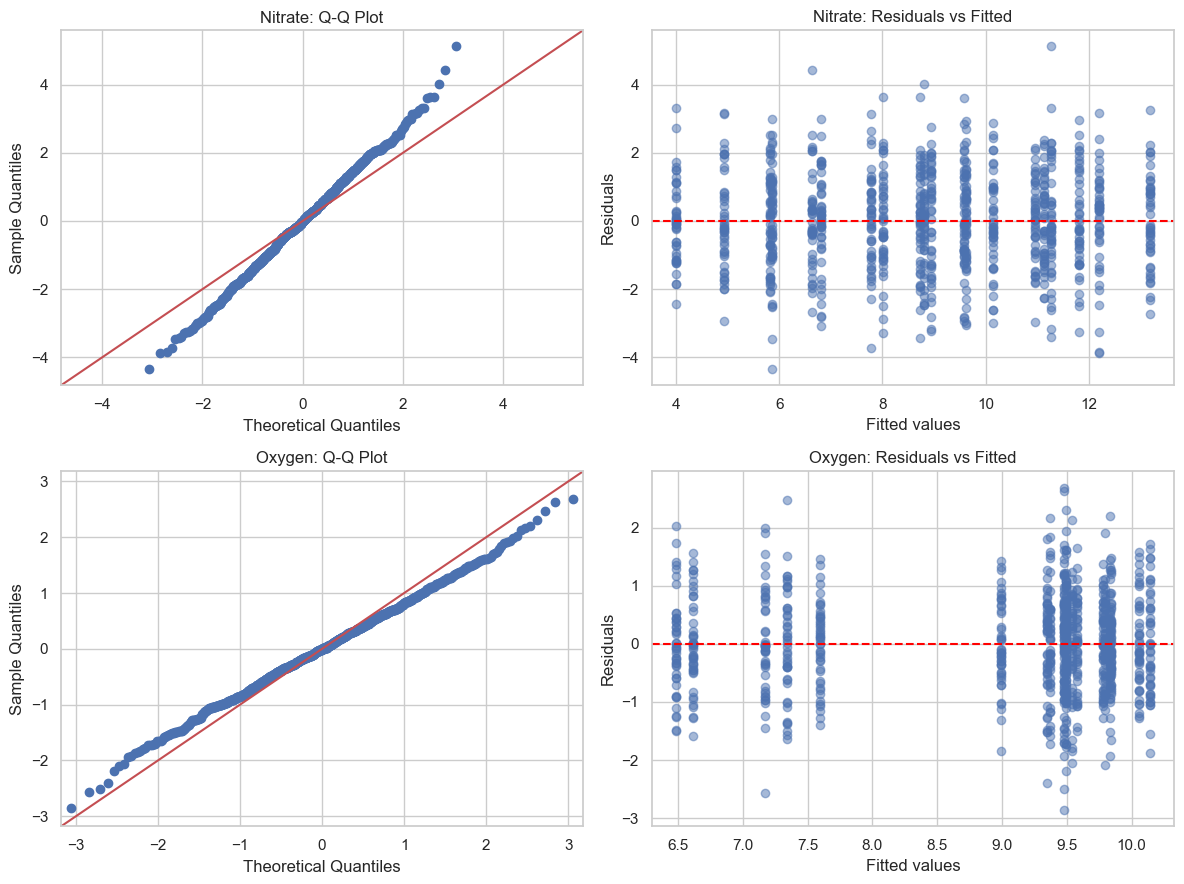

In [35]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# Nitrate diagnostics
sm.qqplot(nitrate_model.resid, line="45", ax=axes[0, 0])
axes[0, 0].set_title("Nitrate: Q-Q Plot")

axes[0, 1].scatter(nitrate_model.fittedvalues, nitrate_model.resid, alpha=0.5)
axes[0, 1].axhline(0, color="red", linestyle="--")
axes[0, 1].set_title("Nitrate: Residuals vs Fitted")
axes[0, 1].set_xlabel("Fitted values")
axes[0, 1].set_ylabel("Residuals")

# Oxygen diagnostics
sm.qqplot(oxygen_model.resid, line="45", ax=axes[1, 0])
axes[1, 0].set_title("Oxygen: Q-Q Plot")

axes[1, 1].scatter(oxygen_model.fittedvalues, oxygen_model.resid, alpha=0.5)
axes[1, 1].axhline(0, color="red", linestyle="--")
axes[1, 1].set_title("Oxygen: Residuals vs Fitted")
axes[1, 1].set_xlabel("Fitted values")
axes[1, 1].set_ylabel("Residuals")

plt.tight_layout()
plt.show()

In [36]:
df["group"] = (
    df["river_section"].astype(str) + "_" +
    df["saison"].astype(str)
)

nitrate_groups = [
    group["nitrate_mgL"].values
    for _, group in df.groupby("group")
]

oxygen_groups = [
    group["oxygen_mgL"].values
    for _, group in df.groupby("group")
]

nitrate_levene = stats.levene(*nitrate_groups, center="median")
oxygen_levene = stats.levene(*oxygen_groups, center="median")

print("Nitrate Levene test:", nitrate_levene)
print("Oxygen Levene test:", oxygen_levene)

Nitrate Levene test: LeveneResult(statistic=0.7200711394833876, pvalue=0.8005074334740242)
Oxygen Levene test: LeveneResult(statistic=1.0102964975089215, pvalue=0.44585318949296854)


## 7. Discussion

The analysis showed that nitrate concentration varied significantly across both river sections and seasons. Nitrate levels generally increased from the headwaters towards the river mouth, with the highest average concentration recorded in summer and the lowest in winter.

Dissolved oxygen also varied significantly across seasons and river sections. Its seasonal pattern was different from that of nitrate, with the lowest average concentration occurring in summer and the highest in winter. The significant interaction indicated that differences between river sections were not consistent across all seasons.

The Spring–Autumn comparison showed significant differences for both variables at the specified significance level of 0.075. Spring had higher average concentrations of both nitrate and dissolved oxygen than autumn.

Although the diagnostic checks did not show major problems with equal variance or residual patterns, the independence of observations could not be confirmed due to the absence of sampling-design information. The results should therefore be interpreted with this limitation in mind.

## 8. Conclusion

This study examined the variation in nitrate and dissolved oxygen concentrations across five river sections and four seasons using two-way ANOVA.

The results showed significant seasonal and spatial differences in nitrate concentration. All pairwise comparisons between river sections and seasons were statistically significant. For dissolved oxygen, both main effects and their interaction were significant. The post-hoc analysis showed that seasonal and spatial differences depended on the river section and season, respectively.

The planned Spring–Autumn comparisons also showed significant differences in both water quality variables at α = 0.075.

Overall, the analysis identified clear variations in water quality across the river sections and seasons.

The hypothesis tests were evaluated at a significance level of α = 0.075. For nitrate, the null hypotheses of equal means across river sections and seasons were rejected, while the interaction hypothesis was not rejected. For dissolved oxygen, the null hypotheses concerning river section, season and their interaction were all rejected.

The planned Spring–Autumn comparisons also showed significant differences for both variables. The null hypothesis was rejected for nitrate (p < 0.001) and dissolved oxygen (p = 0.054).

The Levene tests did not provide evidence of unequal variances for either variable. These results should be interpreted alongside the model diagnostics and the limitation that independence could not be verified from the available sampling information.